In [6]:
!pip install "git+https://github.com/schmidt-neural-data-science/TDE-DP-GMM.git@main"


  Cloning https://github.com/schmidt-neural-data-science/TDE-DP-GMM.git (to revision main) to /tmp/pip-req-build-nswbi642
  Running command git clone --filter=blob:none --quiet https://github.com/schmidt-neural-data-science/TDE-DP-GMM.git /tmp/pip-req-build-nswbi642
  Resolved https://github.com/schmidt-neural-data-science/TDE-DP-GMM.git to commit 2c829dbed4df8dd7cfe73989d99644e2ea4d6a73
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.7/149.7 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 388.0/388.0 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 30.0 MB/s eta 0:00:00
  Created wheel for nds-toolbox: filename=nds_toolbox-0.1.5-py3-none-any.whl size=30128 sha256=3dd68ea629cd845a31926e101e81c2ea24a78cc7b50ac509e7302fd9fa7cf0a2
  Stored in directory: /tmp/pip-ephem-wheel-cache-1e177hoj/wheels/8d/66/

In [2]:
import nds_toolbox
print(nds_toolbox.__version__)






0.1.5


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pickle
import os

In [5]:

FIG_WIDTH = 7.5
MY_FONT_SIZE = 9

plt.rcParams.update({

    # --- Fonts ---
    "font.size": MY_FONT_SIZE,

    # --- Legend ---
    "legend.fontsize": MY_FONT_SIZE,
    "legend.frameon": False,

    # --- Titles ---
    "figure.titlesize": MY_FONT_SIZE,
    "axes.titleweight": "normal",
    "axes.titlesize": MY_FONT_SIZE,

    # --- Axes ---
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": True,
    "axes.spines.bottom": True,
    "axes.edgecolor": "black",
    "axes.linewidth": 0.8,
    "axes.unicode_minus": True,
    "axes.labelsize": MY_FONT_SIZE,

    # --- Lines & markers ---
    "lines.linewidth": 1.0,
    "lines.markersize": 0.7,

    # --- Ticks ---
    "xtick.labelsize": MY_FONT_SIZE,
    "ytick.labelsize": MY_FONT_SIZE,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.bottom": True,
    "ytick.left": True,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "axes.linewidth": 0.7,
    "xtick.minor.visible": False,
    "ytick.minor.visible": False,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,

    # Grid
    "axes.grid": False,
    "grid.linestyle": ":",
    "grid.linewidth": 0.5,
    "grid.alpha": 0.5,

    # --- Layout ---
    "figure.autolayout": True,

    # --- DPI ---
    "savefig.dpi": 600,
    "figure.dpi": 300,
})


In [8]:
from nds_toolbox.sim.bursts.simulator import simulate_bursty_signal
from nds_toolbox.preprocessing.features import (compute_tde,trim_data)
from nds_toolbox.preprocessing.features import choose_embedding_dim

# Simulate a signal with oscillatory bursts

We simulate a single recording that switches between three states. In state 0, we observe only background noise. In state 1, a 20 Hz oscillation is added to that noise. In state 2, a 40 Hz oscillation is added instead. Later, we apply time-delay embedding to the observed signal, fit the DP-GMM, and compare its inferred states with these known labels.

### Recording and state sequence

- `n_seconds`, `fs`, and `time_vec` define a three-minute recording sampled at 250 Hz (45,000 samples). The simulator uses the length of `time_vec` to determine how many samples to generate and `fs` to convert cycles and seconds into samples.
- `freq = [20, 40]` gives the frequency in Hz of each burst state. Adding one baseline state gives `true_num_states = 3`.
- `state_transition` controls which state the simulator draws when a segment ends.
    - `"return_to_baseline"` (used here) places a noise-only interval between bursts. From baseline, 20 Hz and 40 Hz are equally likely.
    - `"uniform_except_self"` gives every other state equal probability. A 20 Hz burst can lead directly to a 40 Hz burst or to baseline, each with probability 0.5.
    - `"uniform"` gives all states equal probability, including the current state. Two successive segments can therefore have the same label.
- `burst_cycles_param = [3, 12]` draws a whole number of cycles from 3 through 12, with equal probability, for each burst. Duration in seconds is cycles divided by frequency. A six-cycle burst therefore lasts 300 ms at 20 Hz and 150 ms at 40 Hz.
- `noise_duration_param = [0.5, 2]` draws the length of each baseline interval uniformly between 0.5 and 2 seconds. Longer intervals leave more of the recording in the baseline state.

###  Ampitude variability and aperiodic noise

- `burst_amp_sigma = 0.1` controls how much amplitudes vary from burst to burst. Each burst gets an amplitude multiplier drawn from a normal distribution with mean 1 and standard deviation 0.1, then converted to its absolute value.
- `beta = 1` generates pink noise, whose expected power decreases with frequency as $1/f$. A value of 0 gives white noise and 2 gives brown noise. This background is present throughout the recording, including during bursts.
- `snr_db = 2` sets the signal-to-noise ratio for each burst state. The simulator scales the 20 Hz bursts together and the 40 Hz bursts together, preserving amplitude differences within each state. At 2 dB, the mean burst power in each state is about 1.58 times the reference noise power.

`seed = 2026` initializes the random number generator, `rng`. Rerunning the entire cell recreates the same state sequence, burst amplitudes, and noise. The call `simulate_bursty_signal(**sim_params)` passes each dictionary entry as a named argument and returns the observed `signal`, its two components (`bursts` and `noise`), and the ground-truth `states` at each sample.

In [48]:
# Set the seed for reproducibility.
seed = 2026
rng = np.random.default_rng(seed)

n_seconds = 60 * 3
fs = 250  # Hz
time_vec = np.linspace(0, n_seconds, int(fs * n_seconds))
simulated_freq = np.array([20, 40])
true_num_states = len(simulated_freq) + 1
snr_db = 0
state_transition = "return_to_baseline"


sim_params = {
    "time_vec": time_vec,
    "fs": fs,
    "freq": simulated_freq,
    "state_transition": state_transition,
    "burst_cycles_param": [3, 12],       # cycles per burst
    "noise_duration_param": [0.5, 2],    # seconds between bursts
    "snr_db": snr_db,
    "burst_amp_sigma": 0.1,
    "beta": 1,           # 0 for white noise, 1 for pink noise, 2 for brown noise
    "rng": rng,
}

signal_dict = simulate_bursty_signal(**sim_params)


In [49]:

print(signal_dict.keys())

signal = signal_dict["signal"]
states = signal_dict["states"]
bursts = signal_dict["bursts"]
noise = signal_dict["noise"]


print("signal shape: ", signal.shape)
print("states shape: ", states.shape)
print("bursts shape: ", bursts.shape)
print("noise shape: ", noise.shape)

true_states_onehot = np.eye(true_num_states)[states]
print(true_states_onehot.shape)

dict_keys(['signal', 'states', 'bursts', 'noise'])
signal shape:  (45000,)
states shape:  (45000,)
bursts shape:  (45000,)
noise shape:  (45000,)
(45000, 3)


In [50]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from nds_toolbox.preprocessing.features import compute_wavelet


def plot_bursty_signal(signal_dict, fs, plot_t=20, *, simulated_freq=None, figsize=(7.5, 3),
                      f_max=80, display_f_max=55):
    """Plot the first plot_t seconds of a simulate_bursty_signal result.

    fs is the sampling rate in Hz. Pass the simulator's freq to label each
    burst state in Hz, including states absent from the plotted window.
    f_max sets the wavelet's upper frequency; display_f_max limits the view.
    Returns the figure and the signal, wavelet, and state axes (top to bottom).
    """
    signal = np.asarray(signal_dict["signal"])
    bursts = np.asarray(signal_dict["bursts"])
    states = np.asarray(signal_dict["states"])
    if signal.ndim != 1 or signal.shape != bursts.shape or signal.shape != states.shape:
        raise ValueError("signal, bursts, and states must be equal-length 1D arrays.")
    if not (np.isfinite(fs) and fs > 0 and np.isfinite(plot_t) and plot_t > 0):
        raise ValueError("fs and plot_t must be finite and positive.")
    n = min(signal.size, round(plot_t * fs))
    if n < 2:
        raise ValueError("The plotted interval must contain at least two samples.")

    if not np.issubdtype(states.dtype, np.integer) or states.min() < 0:
        raise ValueError("states must contain nonnegative integer labels.")
    labels = ["Noise"]
    if simulated_freq is None:
        labels.extend(f"State {i}" for i in range(1, states.max() + 1))
    else:
        labels.extend(f"{hz:g} Hz" for hz in np.atleast_1d(simulated_freq))
        if states.max() >= len(labels):
            raise ValueError("Provide one frequency for each burst state.")
    colors = ["#E0E0E0"] + [plt.get_cmap("tab10")(i % 10) for i in range(len(labels) - 1)]

    # Use the same sample times for all three panels.
    df = 0.5
    top_hz = np.floor(min(f_max, fs / 2) / df) * df
    visible_hz = min(display_f_max, top_hz)
    if not np.isfinite(visible_hz) or visible_hz <= 1:
        raise ValueError("The plotted frequency range must extend above 1 Hz.")
    t, f, amp = compute_wavelet(signal[:n], fs, f_min=1, f_max=top_hz, df=df)
    duration = n / fs
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=figsize, layout="none",
                             gridspec_kw={"height_ratios": [0.7, 0.6, 0.3]})
    fig.subplots_adjust(left=0.105, right=0.905, bottom=0.14, top=1, hspace=0)
    signal_ax, wavelet_ax, state_ax = axes

    signal_ax.plot(t, 0.3 * signal[:n], lw=0.2, color="black")
    for state in range(1, len(labels)):
        trace = np.where(states[:n] == state, bursts[:n], 0)
        signal_ax.plot(t, 0.3 * (trace - state - 1), lw=0.2, color=colors[state])
    signal_ax.set_axis_off()

    im = wavelet_ax.imshow(amp, extent=(0, duration, f[0] - df/2, f[-1] + df/2),
                           origin="lower", aspect="auto", cmap="viridis")
    wavelet_ax.set(ylabel="Freq. (Hz)", ylim=(1, visible_hz))
    wavelet_ax.yaxis.set_major_locator(MaxNLocator(nbins=3, steps=[1, 2, 5, 10]))
    wavelet_ax.tick_params(axis="x", bottom=False)
    colorbar_ax = wavelet_ax.inset_axes([1.005, 0, 0.02, 1])
    cb = fig.colorbar(im, cax=colorbar_ax)
    cb.ax.tick_params(which="both", length=2, width=0.4, pad=1)
    cb.set_label("Amp. (a.u.)", rotation=270, labelpad=12)

    # Extend the final label through the last sample's full interval.
    state_time = np.append(t, duration)
    state_sequence = np.append(states[:n], states[n - 1])
    state_ax.stackplot(state_time, *(state_sequence == i for i in range(len(labels))),
                       step="post", colors=colors, labels=labels, linewidth=0)
    state_ax.set(xlabel="Time (s)", xlim=(0, duration), ylim=(0, 1), yticks=[])
    state_ax.set_ylabel("True States", rotation=0, labelpad=30, va="center")
    state_ax.xaxis.set_major_locator(MaxNLocator(nbins=20, steps=[1, 2, 5, 10]))

    # Use the fewest columns that keep the legend inside the state strip's height.
    strip = state_ax.get_position()
    for columns in range(1, len(labels) + 1):
        legend = state_ax.legend(loc="upper left", bbox_to_anchor=(1.005, 0.96),
                                 ncols=columns, frameon=False, borderaxespad=0, borderpad=0,
                                 handlelength=1, handletextpad=0.4, columnspacing=0.9,
                                 labelspacing=0.25)
        legend_box = legend.get_window_extent().transformed(fig.transFigure.inverted())
        if legend_box.y0 >= strip.y0 + 0.02 * strip.height:
            break

    # Reserve the width the legend needs, including a small outer margin.
    overflow = legend_box.x1 + 0.01 - 1
    if overflow > 0:
        shrink = min(overflow, strip.width / 2)
        # Widen the canvas only if the legend would take over half the data panels.
        scale = 1 + (overflow - shrink)
        fig.set_figwidth(fig.get_figwidth() * scale)
        fig.subplots_adjust(left=strip.x0 / scale, right=(strip.x1 - shrink) / scale)
    return fig, axes


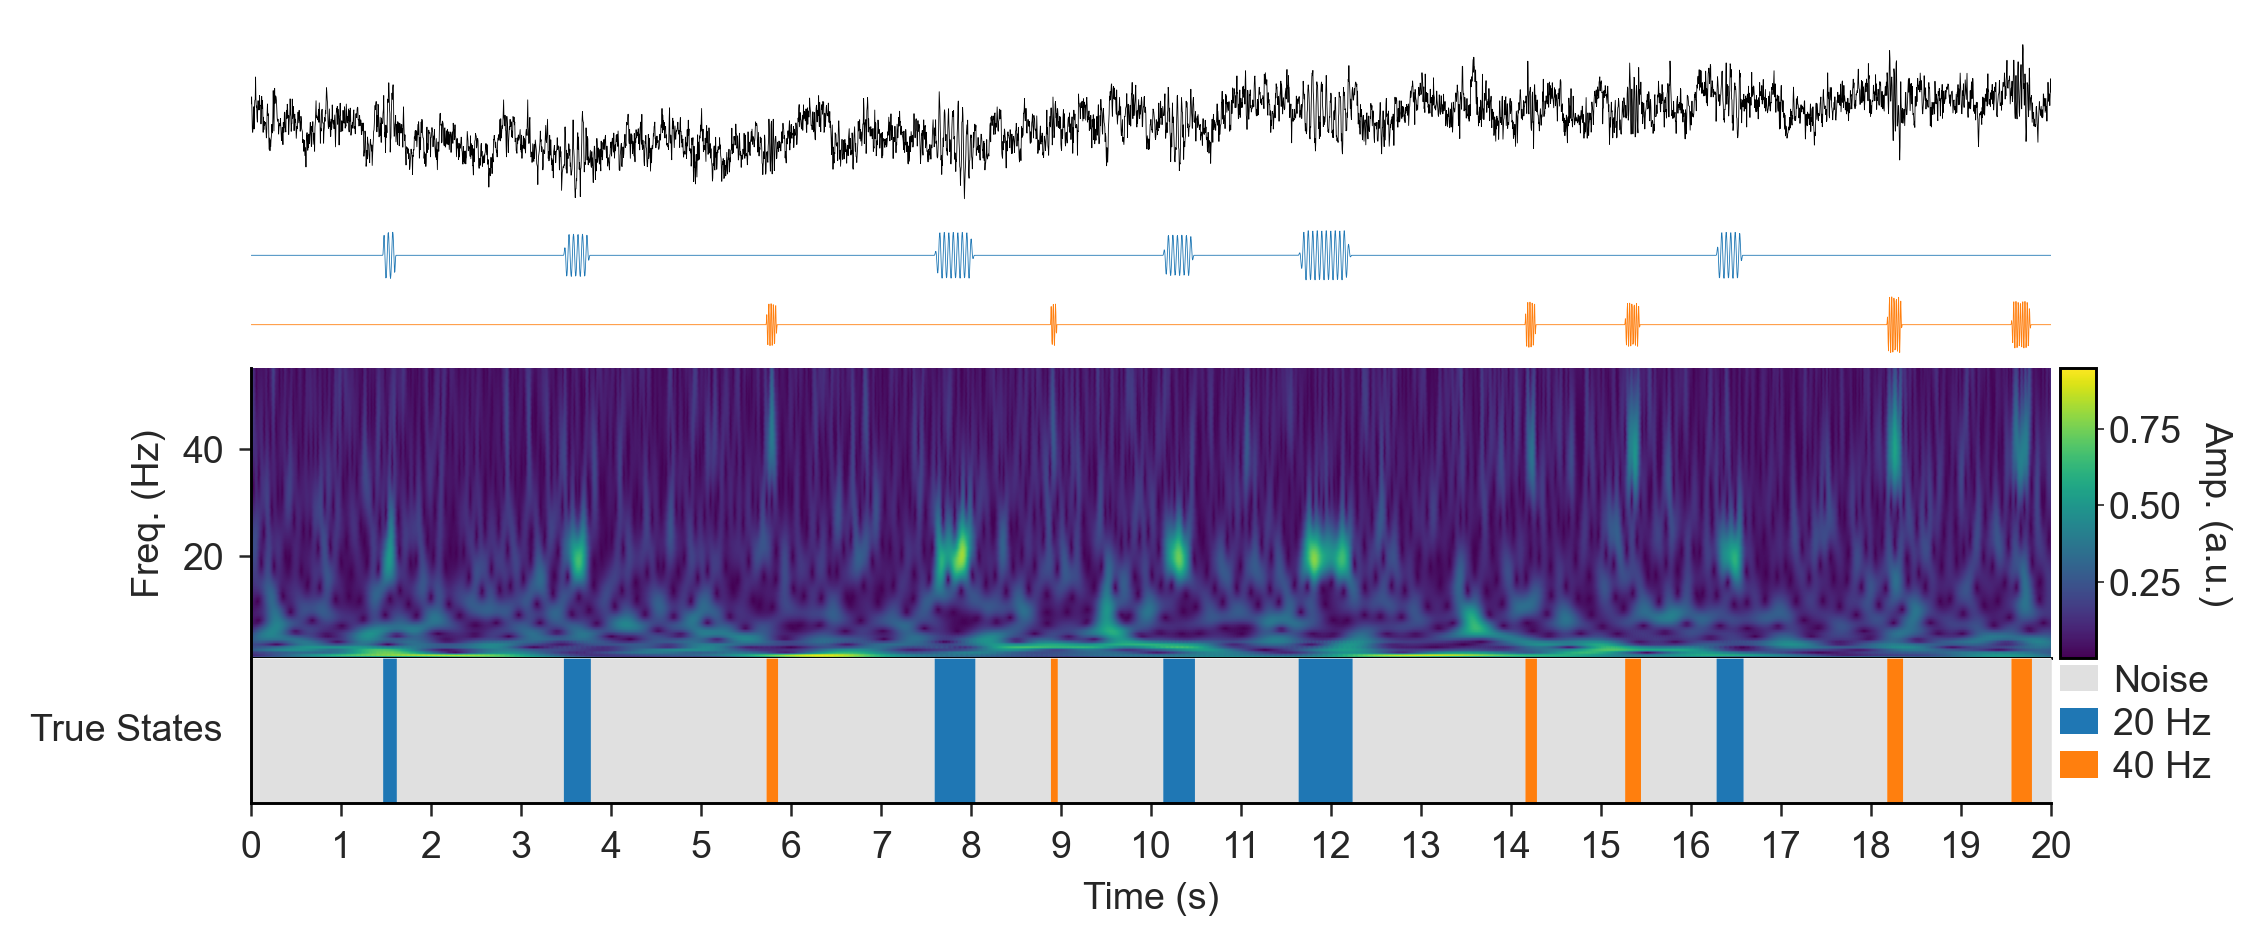

In [51]:
fig, axes = plot_bursty_signal(signal_dict, fs, plot_t=20, simulated_freq=simulated_freq, figsize=(FIG_WIDTH, 3))
plt.show()


# Time delay embedding (TDE)

In [52]:
#step1: standarize the signal before TDE
signal = (signal - np.mean(signal))/ np.std(signal)


#step2: TDE
#number of embeddings is chosen based on 2.5 cycles of the target frequency
#Here we have multiple candidate frequencies, so we use mean frequency as our target

num_emb = choose_embedding_dim(np.mean(freq), fs, min_cycles = 2.5, ensure_odd = True, verbose=True)
#you can also set it to some reasonable embeddings, say num_emb = 15

tde_signal = compute_tde(signal, num_emb)



#after TDE, num_emb//2 data points are lost from both ends of the signal
#so here we trim our signal and true state for later
trimmed_signal = trim_data(signal, num_emb, verbose = False)
trimmed_states = trim_data(states, num_emb, verbose = False)
trimmed_time_vec = np.linspace(0, len(trimmed_states)/fs, len(trimmed_states))


Chosen window size = 0.071 (sec): minimum cycles of 2.5 at 35.0 Hz
Chosen embedding dimension = 19: sampling rate = 250 Hz
9 data points were lost from both ends.
data shape: (44982, 19)


In [53]:
#roughly speaking, the expected number of states is "ln n"
num_states = int(np.ceil(np.log(len(trimmed_signal)))) # E[K] = alpha ln n
# this sets K above the expected occupied clusters

#num_states = 3 (if you wanna test with the ground truth)

num_models = 1 #default: 10
num_epochs = 3000 #default: 3000
n_jobs = 1 #increase the number of jobs when you want to multi process the inference


In [54]:

from nds_toolbox.models.dpgmm_numpyro import fit_DPGMM, truncate, get_states


In [55]:
dpgmm_result = fit_DPGMM(data=tde_signal,
                             num_states=num_states,
                             use_epoch_tqdm=False,
                             n_jobs=n_jobs,
                             use_model_tqdm=True,
                             num_models=num_models,
                             main_seed=seed,
                         num_epochs = num_epochs,
                             verbose=True)

#took about 1 min

Fitting 1 DPGMM models:   0%|          | 0/1 [00:00<?, ?model/s]

KeyboardInterrupt: 

In [16]:
est_params = dpgmm_result["est_params"]
loss_best = dpgmm_result["loss_best"]
loss_all = dpgmm_result["loss_all"]


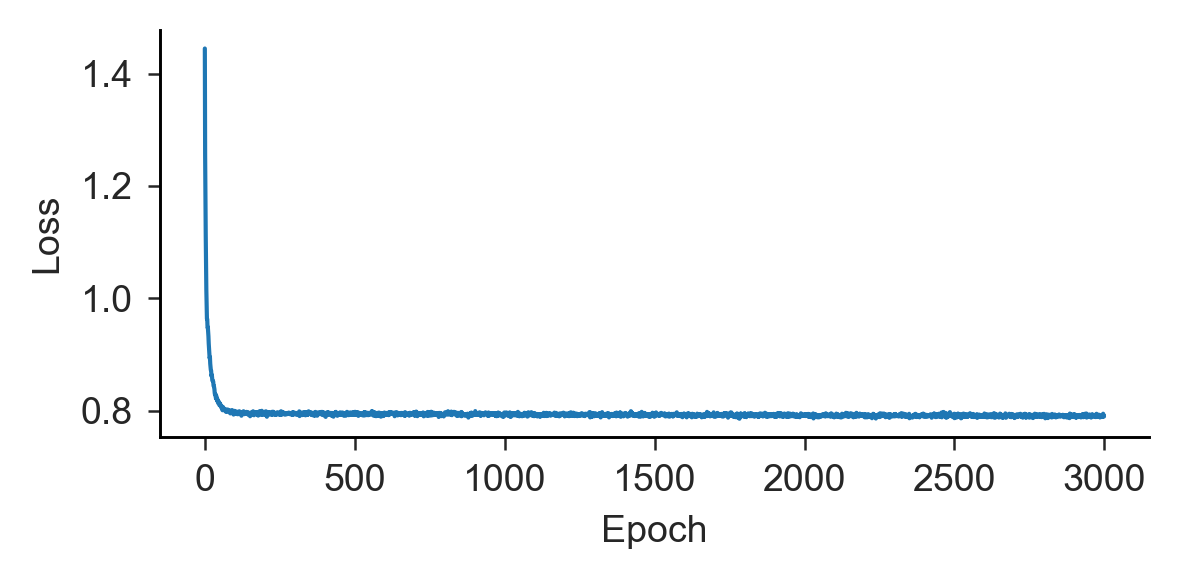

In [17]:
fig, ax = plt.subplots(figsize=(4, 2))
ax.plot(np.array(loss_all).T)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
plt.show()

In [18]:
from nds_toolbox.utils.helper import match_states
from sklearn.metrics import matthews_corrcoef


est_params = dpgmm_result["est_params"]
alpha = est_params["alpha"]
weights = est_params["weights"]
means = est_params["means"]
covs = est_params["covs"]

#truncate tiny mixture weights and renormalize the weights
trunc_means, trunc_covs, trunc_weights, trunc_info = truncate(means, covs, weights, verbose=True, return_info=True)


#effeci
num_effective_states = len(trunc_weights)


#get the estimated states based on the learned parameters
est_states_dpgmm = get_states(tde_signal, trunc_means, trunc_covs, trunc_weights)

#one hot vector of estimated states
est_states_dpgmm_onehot = np.eye(num_effective_states)[est_states_dpgmm]


#one hot vector of true states
trimmed_states_onehot = np.eye(num_effective_states)[trimmed_states]



#order the estimated states
order, est_states_dpgmm_onehot = match_states(trimmed_states_onehot, est_states_dpgmm_onehot, verbose=False)
#onehot vector -> a signal array
est_states_dpgmm = np.argmax(est_states_dpgmm_onehot, axis=1)




[truncate]
  total components              : 11
  mass threshold                : 0.990

  Stage 1: mass truncation
    kept components             : 4
    kept original indices       : [1, 2, 8, 10]
    retained weight mass        : 0.9995
    dropped weight mass         : 0.0005

  Stage 2: edge-state removal
    CV threshold                : 0.100
    removed components          : 0
    removed original indices    : []
    CVs in active set           : [0.0231, 0.0749, 0.0298, 0.0264]

  Final result
    final components kept       : 4
    final original indices      : [1, 2, 8, 10]
    final retained weight mass  : 0.9995
    final dropped weight mass   : 0.0005


In [19]:

mcc_dpgmm = matthews_corrcoef(trimmed_states, est_states_dpgmm)
print()
print("mcc" ,mcc_dpgmm)



mcc 0.8545521505371463


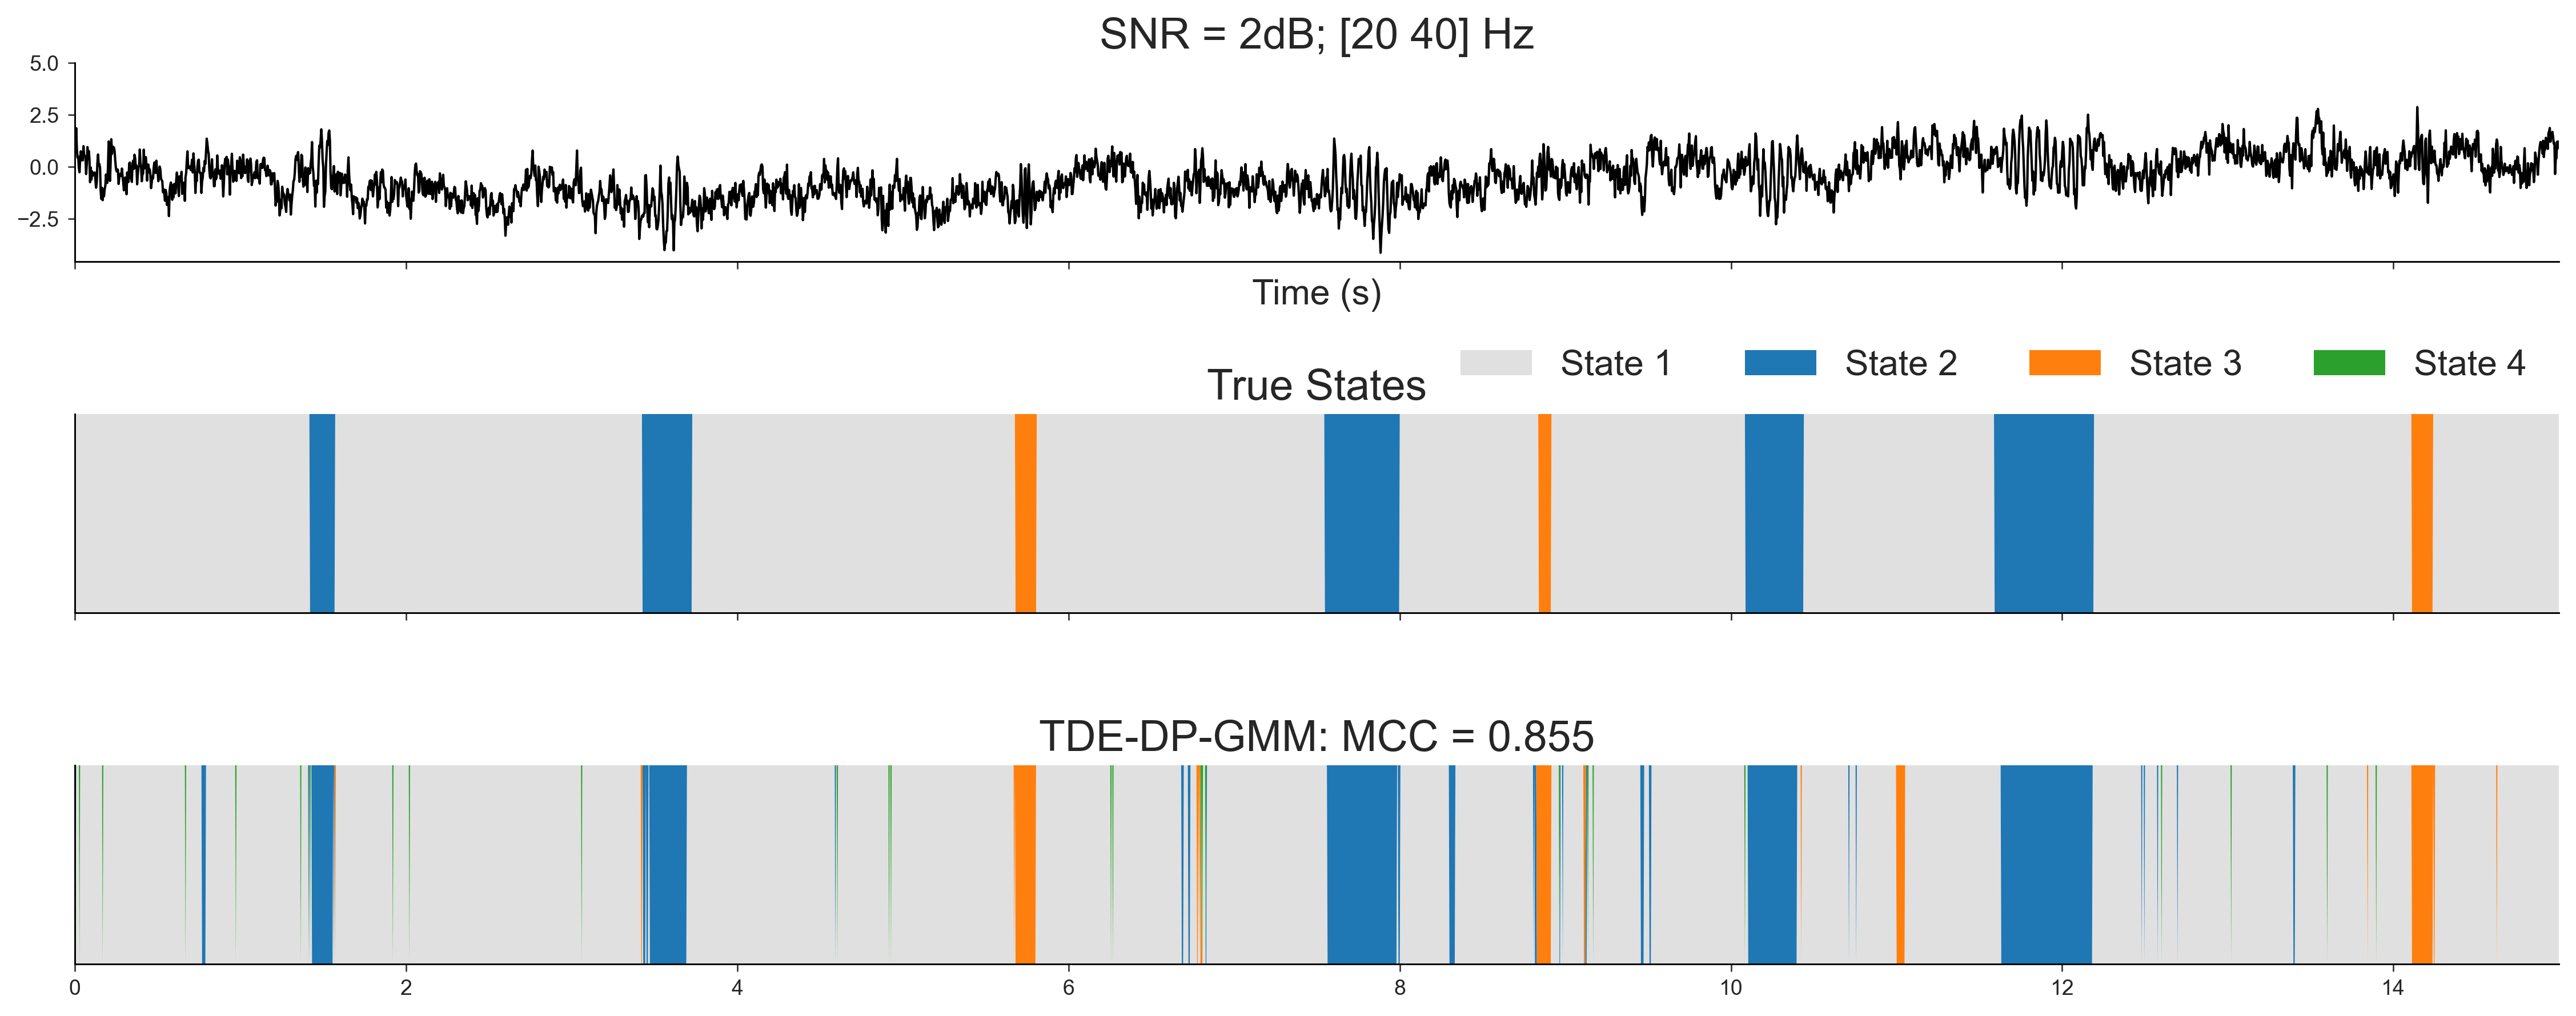

In [20]:

cmap = plt.get_cmap("tab10")
colors = [cmap(i) for i in range(num_states)]
grey = ["#E0E0E0"]
colors = grey + colors
state_labels = [f"State {i+1}" for i in range(num_states)]

fig, ax = plt.subplots(3, 1, figsize = (15, 6), sharex = True)

ax[0].plot(trimmed_time_vec, trimmed_signal, color = "k")
ax[0].set_xlabel("Time (s)", fontsize = 15)
ax[0].set_title(f"SNR = {snr_db}dB; {freq} Hz", fontsize = 18)
ax[0].set_xlim(0, 15)


ax[1].stackplot(trimmed_time_vec, trimmed_states_onehot.T, colors = colors, labels = state_labels, linewidth = 0)
ax[1].set_title("True States", fontsize = 18)
ax[1].set_ylim(0, 1)
ax[1].set_yticks([])



ax[2].stackplot(trimmed_time_vec, est_states_dpgmm_onehot.T, colors = colors, linewidth = 0)
ax[2].set_title(f"TDE-DP-GMM: MCC = {np.round(mcc_dpgmm, 3)}", fontsize = 18)
ax[2].set_ylim(0, 1)
ax[2].set_yticks([])


ax[1].legend(
    loc="lower right",
    bbox_to_anchor=(1.0, 1.0),
    ncol=num_states,
    frameon=False,
    fontsize=15,
)



plt.tight_layout()
plt.show()



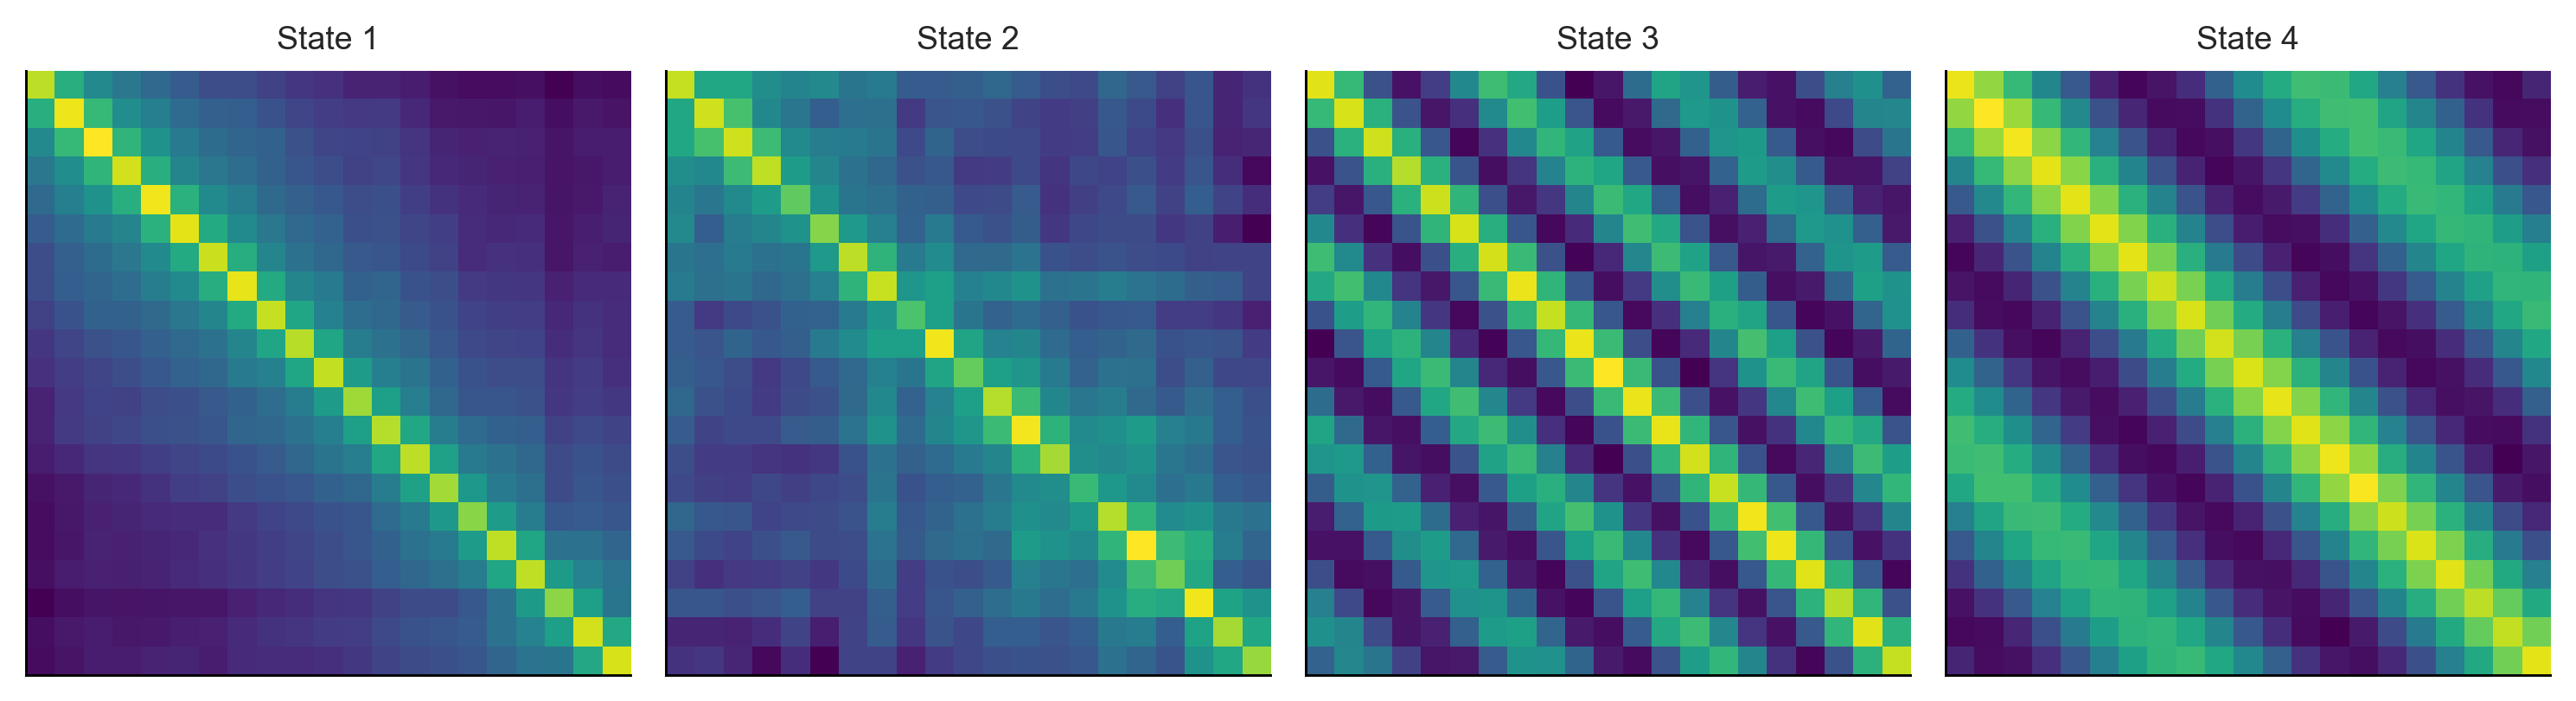

In [22]:


fig, ax = plt.subplots(1, trunc_covs.shape[0], figsize=(10, 6), sharex=True, sharey=True)

for i, cov in enumerate(trunc_covs):
    ax[i].imshow(cov, cmap="viridis")
    ax[i].set_title(f"State {i+1}")
    ax[i].set_xticks([])
    ax[i].set_yticks([])

plt.show()


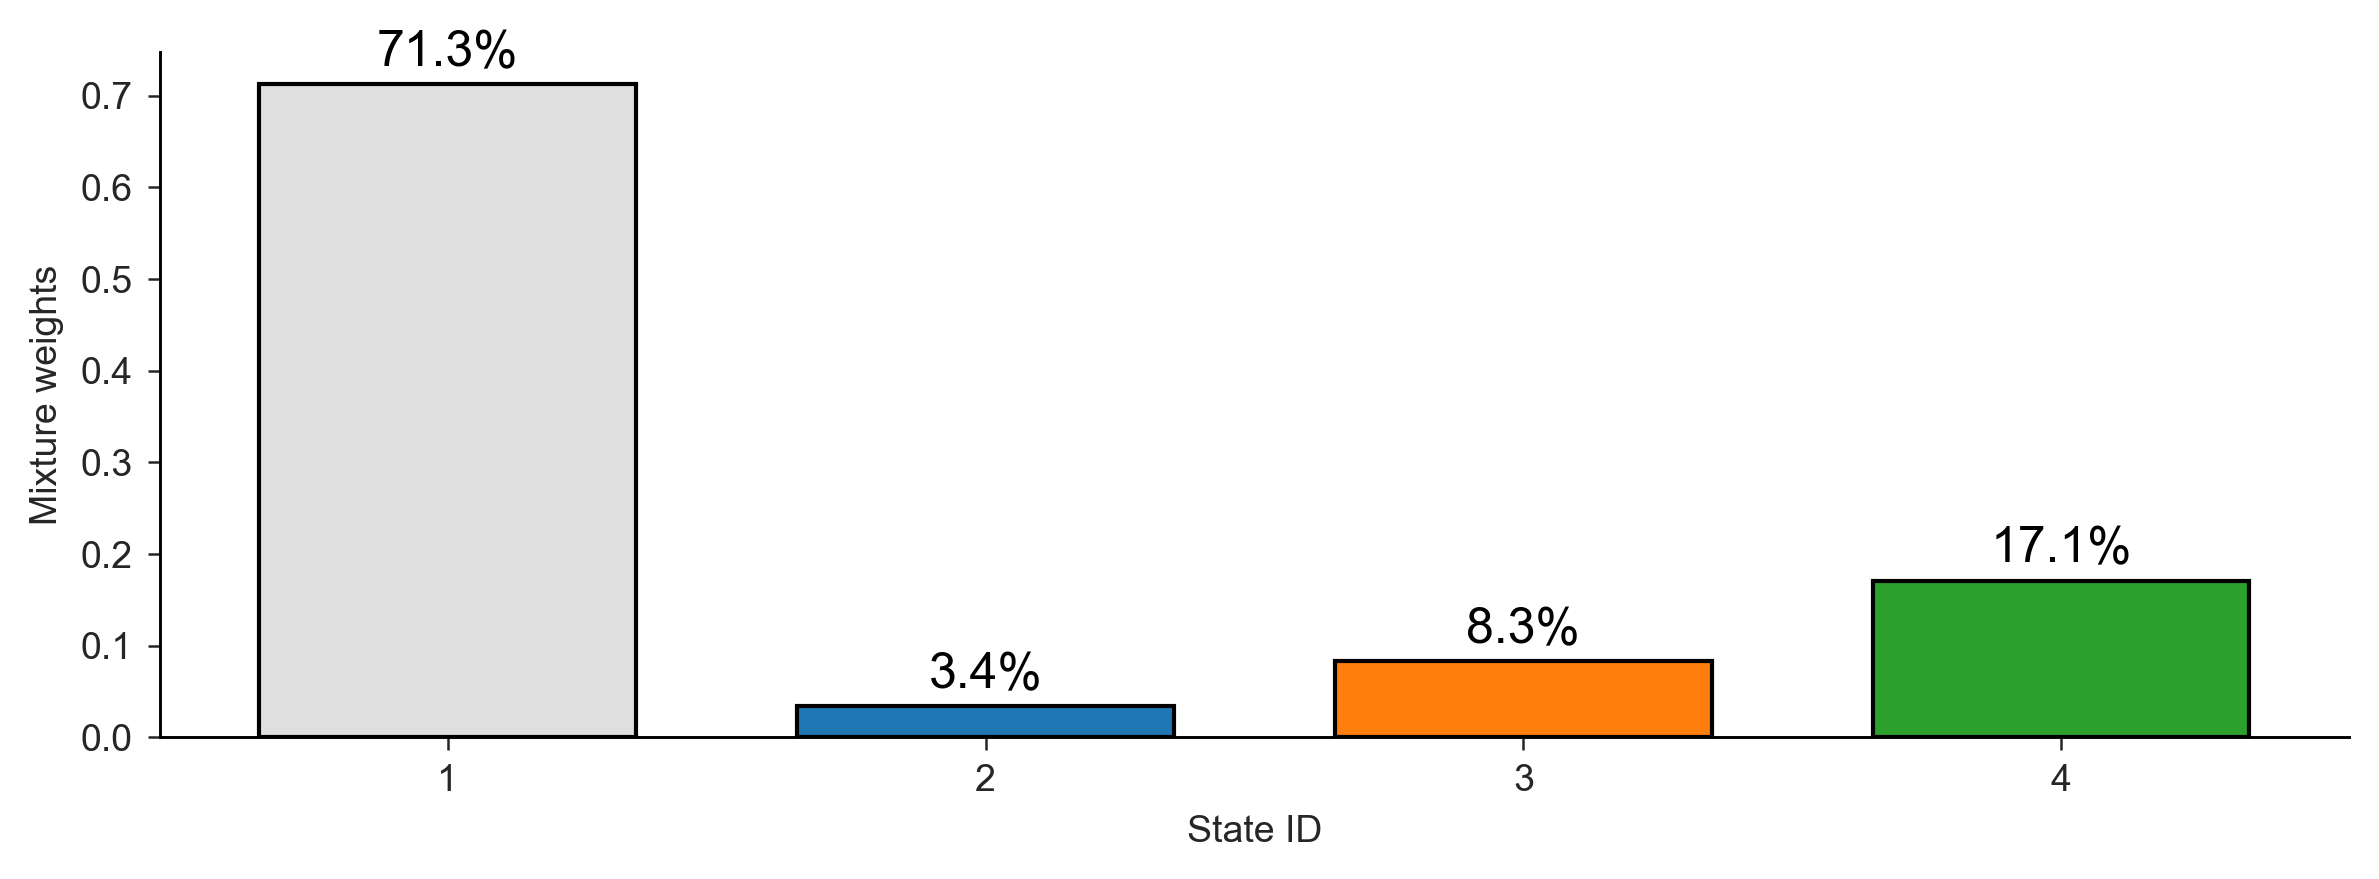

In [23]:

fig, ax = plt.subplots(1, 1, figsize=(8, 3))

for k, w in enumerate(trunc_weights):
        ax.bar(
            k,
            w,
            width=0.7,
            color=colors[k],
            zorder=1,
            align="center",
            edgecolor="k",
        )
        ax.text(
            k,
            w + 0.02,
            f"{w * 100:.1f}%",
            ha="center",
            color="k",
            fontsize=12,
        )

ax.set_ylabel("Mixture weights")
ax.set_xlabel("State ID")
ax.set_xticks(np.arange(num_effective_states), labels=np.arange(1, num_effective_states + 1))
plt.show()